# FP32 Baseline: Magic Wand Gesture Model

CSCE 4930, Hardware Architecture for AI and ML. 

This notebook:
1. Loads the raw Magic Wand accelerometer logs from `data/`.
2. Cleans and segments them into individual gesture performances.
3. Splits them by participant (train / validation / test), as the project spec requires.
4. Pads/truncates each performance to a fixed 128 x 3 window and augments the training set.
5. Builds and trains the baseline CNN, then evaluates it on the held-out test set (target: at least 90% accuracy).
6. Stores the trained model (`.keras`, SavedModel and FP32 `.tflite`) and the exact test tensors, for the later desktop-vs-device comparison.

Environment: Python 3.9, TensorFlow 2.15 (Keras 2). See `requirements.txt`.

In [1]:
import csv
import json
import os
import random
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.metrics import confusion_matrix, classification_report

print("TensorFlow", tf.__version__, "| NumPy", np.__version__)

SEED = 42
tf.keras.utils.set_random_seed(SEED)       # seeds Python, NumPy and TF
tf.config.experimental.enable_op_determinism()
rng = np.random.default_rng(SEED)

PROJECT_ROOT = Path.cwd()
DATA_DIR = PROJECT_ROOT / "data"
MODEL_DIR = PROJECT_ROOT / "models" / "fp32"
PROCESSED_DIR = PROJECT_ROOT / "processed"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

# Class order defines the output index of the softmax layer (and must match the firmware).
GESTURES = ["wing", "ring", "slope", "negative"]
SEQ_LEN = 128             # model input: 128 time steps x 3 axes x 1 channel
DIM = 3
NEG_CHUNK = 120           # negative recordings are continuous; cut them into fixed chunks
INPUT_SCALE = 1.0 / 1000  # mg -> g. Raw mg values (up to ~±2000) make training collapse; the firmware must apply the same scale

# Participant-based split from the project specification.
SPLIT = {
    "train": ["hyw", "shiyun", "tangsy", "dengyl", "jiangyh", "xunkai", "negative3"],
    "val":   ["pengxl", "negative2", "negative4"],
    "test":  ["liucx", "zhangxy", "negative1", "negative5"],
}
EXPECTED_COUNTS = {"train": 434, "val": 92, "test": 155}


TensorFlow 2.15.1 | NumPy 1.26.4


## 1. Load the raw data

Each gesture file (`data/<gesture>/output_<gesture>_<user>.txt`) is a serial-terminal capture. It contains:
* terminal noise at the top (`Script started ...`, escape sequences, binary garbage), and
* about 15 to 40 performances, each started by a `-,-,-` marker line and followed by one `x,y,z` reading per row (25 Hz).

Negative files have a single `-,-,-` marker followed by one long continuous recording. Following the original Magic Wand pipeline, these are cut into chunks of 120 readings. The reading that would start a new chunk is dropped; this is the original pipeline's behaviour and reproduces the sample counts given in the spec.

Cleaning rules applied while parsing:
* Ignore macOS resource-fork files (`._*`) and the stray `.ipynb_checkpoints` folder.
* Keep only CSV rows with exactly 3 fields; drop rows that do not parse as 3 finite floats (terminal noise).
* Drop empty segments, e.g. two consecutive `-,-,-` markers.

In [2]:
def parse_row(fields):
    # Return [x, y, z] as floats, or None if the row is not a valid reading.
    if len(fields) != 3:
        return None
    try:
        row = [float(v) for v in fields]
    except ValueError:
        return None
    return row if all(np.isfinite(row)) else None


def load_gesture_file(path):
    # Split a gesture capture into performances at every '-,-,-' marker.
    segments, current, dropped = [], [], 0
    with open(path, "r", errors="ignore") as f:
        for fields in csv.reader(f):
            if len(fields) == 3 and fields[2].strip() == "-":       # performance marker
                if current:
                    segments.append(current)
                current = []
                continue
            row = parse_row(fields)
            if row is None:
                dropped += 1
            else:
                current.append(row)
    if current:
        segments.append(current)
    return segments, dropped


def load_negative_file(path):
    # Cut a continuous negative recording into chunks of NEG_CHUNK readings.
    segments, current, dropped = [], [], 0
    with open(path, "r", errors="ignore") as f:
        for fields in csv.reader(f):
            if len(fields) == 3 and fields[2].strip() == "-":
                continue
            row = parse_row(fields)
            if row is None:
                dropped += 1
                continue
            if len(current) == NEG_CHUNK:   # chunk full: emit it (this reading is skipped, as in the original pipeline)
                segments.append(current)
                current = []
            else:
                current.append(row)
    if current:
        segments.append(current)
    return segments, dropped


samples = []   # one dict per performance
file_log = []
for gesture in GESTURES:
    for path in sorted((DATA_DIR / gesture).glob("output_*.txt")):   # skips '._*' and checkpoint dirs
        user = path.stem[len(f"output_{gesture}_"):]
        if gesture == "negative":
            user = "negative" + user              # e.g. negative3, negativeccw_1
            segments, dropped = load_negative_file(path)
        else:
            segments, dropped = load_gesture_file(path)
        for seg in segments:
            samples.append({"gesture": gesture, "label": GESTURES.index(gesture),
                            "user": user, "data": np.asarray(seg, dtype=np.float32)})
        file_log.append({"file": f"{gesture}/{path.name}", "user": user,
                         "performances": len(segments), "dropped_rows": dropped})

file_df = pd.DataFrame(file_log)
print(f"Loaded {len(samples)} performances from {len(file_df)} files")
file_df

Loaded 785 performances from 38 files


,file,user,performances,dropped_rows
0,wing/output_wing_dengyl.txt,dengyl,20,368
1,wing/output_wing_hyw.txt,hyw,40,712
2,wing/output_wing_jiangyh.txt,jiangyh,21,378
3,wing/output_wing_liucx.txt,liucx,20,360
4,wing/output_wing_lsj.txt,lsj,22,405
5,wing/output_wing_pengxl.txt,pengxl,19,338
6,wing/output_wing_shiyun.txt,shiyun,27,487
7,wing/output_wing_tangsy.txt,tangsy,10,186
8,wing/output_wing_xunkai.txt,xunkai,23,415
9,wing/output_wing_zhangxy.txt,zhangxy,21,379


## 2. Inspect and clean

Performance length (rows): min=14, median=78, max=175, > 128: 4
Value range per axis (mg): [-1388. -2040. -2040.] to [2040. 2040. 2040.]
NaN/inf values: 0


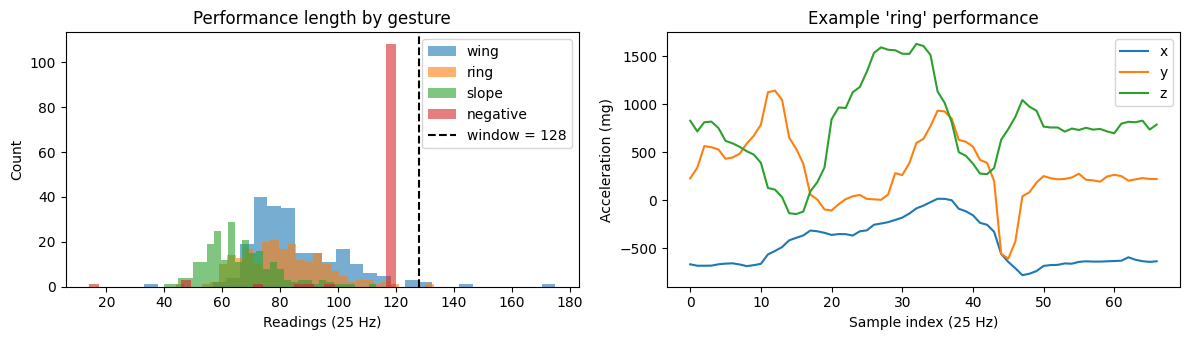

In [3]:
lengths = np.array([len(s["data"]) for s in samples])
all_vals = np.concatenate([s["data"] for s in samples])
print(f"Performance length (rows): min={lengths.min()}, median={np.median(lengths):.0f}, "
      f"max={lengths.max()}, > {SEQ_LEN}: {(lengths > SEQ_LEN).sum()}")
print("Value range per axis (mg):", all_vals.min(axis=0), "to", all_vals.max(axis=0))
print("NaN/inf values:", int((~np.isfinite(all_vals)).sum()))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for g in GESTURES:
    axes[0].hist([len(s["data"]) for s in samples if s["gesture"] == g], bins=30, alpha=0.6, label=g)
axes[0].axvline(SEQ_LEN, color="k", ls="--", label=f"window = {SEQ_LEN}")
axes[0].set(title="Performance length by gesture", xlabel="Readings (25 Hz)", ylabel="Count")
axes[0].legend()
ex = next(s for s in samples if s["gesture"] == "ring")["data"]
axes[1].plot(ex)
axes[1].legend(["x", "y", "z"])
axes[1].set(title="Example 'ring' performance", xlabel="Sample index (25 Hz)", ylabel="Acceleration (mg)")
plt.tight_layout()
plt.show()

Samples longer than the 128-step window are truncated to their first 128 readings. Shorter ones are padded (Section 4).

Participant `lsj` and the extra negative recordings (`negativeccw_1`, `negativeccw_2`, `negativejiangyh`) are not part of the spec's split, so they are excluded.

## 3. Participant-based split

In [4]:
splits = {name: [s for s in samples if s["user"] in users] for name, users in SPLIT.items()}
used = {u for users in SPLIT.values() for u in users}
excluded = Counter(s["user"] for s in samples if s["user"] not in used)
print("Excluded (not in spec split):", dict(excluded))

rows = []
for name, items in splits.items():
    c = Counter(s["gesture"] for s in items)
    rows.append({"split": name, **{g: c[g] for g in GESTURES}, "total": len(items),
                 "expected": EXPECTED_COUNTS[name]})
split_df = pd.DataFrame(rows).set_index("split")
total = split_df["total"].sum()
split_df["share"] = (split_df["total"] / total * 100).round(1).astype(str) + "%"
display(split_df)

for name, items in splits.items():
    assert len(items) == EXPECTED_COUNTS[name], f"{name}: {len(items)} != {EXPECTED_COUNTS[name]}"
print("Split sizes match the project specification.")

Excluded (not in spec split): {'lsj': 68, 'negativeccw_1': 22, 'negativeccw_2': 6, 'negativejiangyh': 8}


,wing,ring,slope,negative,total,expected,share
split,,,,,,,
train,141,134,140,19,434,434,63.7%
val,19,20,20,33,92,92,13.5%
test,41,42,44,28,155,155,22.8%


Split sizes match the project specification.


## 4. Windowing, padding and augmentation

**Padding** (from the Magic Wand pipeline): a short performance is placed in a 128-step window. The unused steps are filled with the performance's first (or last) reading plus small uniform noise (±10 mg). This mimics the device being held still before or after the gesture.

**Scaling:** after windowing, every value is multiplied by `INPUT_SCALE` (mg -> g). With raw mg inputs the network did not train: it stayed near chance accuracy with Adam at lr 1e-3 or 1e-4. The model itself is unchanged; the firmware just has to divide its accelerometer readings (in mg) by 1000 before filling the input tensor.

* **Validation/test:** one deterministic window per performance (seeded noise). The gesture is aligned to the *end* of the window, the same as in the on-device ring buffer, where the latest reading is last. This keeps 92 and 155 examples, and the saved test tensors can be replayed on the device bit-for-bit.
* **Training:** each performance is first augmented (original + random offset, random scaling and random time-warping), and each variant is padded both *before* and *after*. This makes the model robust to where the gesture falls in the window.

In [5]:
NOISE_LEVEL = 20   # padding noise amplitude (mg), as in the original pipeline


def pad_window(data, mode, gen):
    # Place `data` in a SEQ_LEN window: 'before' = gesture at end, 'after' = gesture at start.
    n = min(len(data), SEQ_LEN)
    data = data[:SEQ_LEN]
    if mode == "before":
        win = (gen.random((SEQ_LEN, DIM)) - 0.5) * NOISE_LEVEL + data[0]
        win[SEQ_LEN - n:] = data
    else:
        win = (gen.random((SEQ_LEN, DIM)) - 0.5) * NOISE_LEVEL + data[-1]
        win[:n] = data
    return win.astype(np.float32)


def time_warp(data, gen):
    # Resample a performance to a random 0.8x to 1.25x of its length (speed variation).
    factor = gen.uniform(0.8, 1.25)
    new_len = max(2, int(round(len(data) * factor)))
    src = np.linspace(0, len(data) - 1, new_len)
    return np.stack([np.interp(src, np.arange(len(data)), data[:, k]) for k in range(DIM)], axis=1)


def augment(data, gen, n_offset=4, n_scale=4, n_warp=4):
    variants = [data]
    variants += [data + gen.uniform(-100, 100, size=(1, DIM)) for _ in range(n_offset)]   # sensor bias
    variants += [data * gen.uniform(0.9, 1.1) for _ in range(n_scale)]                    # gesture amplitude
    variants += [time_warp(data, gen) for _ in range(n_warp)]                             # gesture speed
    return variants


def build_train_set(items, gen):
    X, y = [], []
    for s in items:
        for v in augment(s["data"], gen):
            for mode in ("before", "after"):
                X.append(pad_window(v, mode, gen))
                y.append(s["label"])
    return np.stack(X)[..., np.newaxis], np.asarray(y, dtype=np.int32)


def build_eval_set(items, seed):
    gen = np.random.default_rng(seed)
    X = np.stack([pad_window(s["data"], "before", gen) for s in items])[..., np.newaxis]
    y = np.asarray([s["label"] for s in items], dtype=np.int32)
    return X, y


x_train, y_train = build_train_set(splits["train"], rng)
x_val, y_val = build_eval_set(splits["val"], seed=1)
x_test, y_test = build_eval_set(splits["test"], seed=2)

### Balancing the negative class (training set only)

The spec's training split has only **19 negative** performances (all from `negative3`) against 415 gesture performances. A first run on that data alone confused most real negatives in validation and test with wing, ring or slope; the three gestures themselves were classified almost perfectly. Two kinds of extra negatives are therefore added to the **training set only**. The validation and test sets are untouched.

1. **Random crops of the training negative stream:** windows of random length (60 to 128) at random offsets in the `negative3` recording, with random offset or scale and random padding side. These use only data from the training participant.
2. **Synthetic negatives** (from the original Magic Wand `data_prepare.py`): 100 slow straight-line drifts, 100 uniform-random signals and 100 "held still" signals.

This configuration was chosen on **validation** accuracy (compared with no extra negatives, class weights only, and fewer crops). The test set was not used to choose it.

In [6]:
N_NEG_CROPS = 1000
N_SYNTH_PER_KIND = 100


def negative_crops(stream, n, gen):
    X = []
    for _ in range(n):
        length = int(gen.integers(60, SEQ_LEN + 1))
        start = int(gen.integers(0, len(stream) - length))
        seg = stream[start:start + length]
        seg = seg + gen.uniform(-100, 100, size=(1, DIM)) if gen.random() < 0.5 else seg * gen.uniform(0.9, 1.1)
        X.append(pad_window(seg, "before" if gen.random() < 0.5 else "after", gen))
    return np.stack(X)


def synthetic_negatives(n, gen):
    t = np.arange(SEQ_LEN)[:, None]
    drift = [(gen.random(DIM) - 0.5) * 2000 + t * (gen.random(DIM) - 0.5) * 10
             + (gen.random((SEQ_LEN, DIM)) - 0.5) * 6 for _ in range(n)]
    noise = [(gen.random((SEQ_LEN, DIM)) - 0.5) * 1000 for _ in range(n)]
    still = [(gen.random(DIM) - 0.5) * 2000 + (gen.random((SEQ_LEN, DIM)) - 0.5) * 40 for _ in range(n)]
    return np.stack(drift + noise + still).astype(np.float32)


neg_label = GESTURES.index("negative")
neg_stream = np.concatenate([s["data"] for s in splits["train"] if s["gesture"] == "negative"])
x_neg = np.concatenate([negative_crops(neg_stream, N_NEG_CROPS, rng),
                        synthetic_negatives(N_SYNTH_PER_KIND, rng)])[..., np.newaxis]
x_train = np.concatenate([x_train, x_neg])
y_train = np.concatenate([y_train, np.full(len(x_neg), neg_label, dtype=np.int32)])

# mg -> g (identical scaling must be applied on the device)
x_train, x_val, x_test = (x * INPUT_SCALE for x in (x_train, x_val, x_test))

for name, (X, y) in {"train": (x_train, y_train), "val": (x_val, y_val), "test": (x_test, y_test)}.items():
    print(f"{name:5s} X={X.shape} {X.dtype}  class counts={np.bincount(y, minlength=len(GESTURES)).tolist()}")

train X=(12584, 128, 3, 1) float32  class counts=[3666, 3484, 3640, 1794]
val   X=(92, 128, 3, 1) float32  class counts=[19, 20, 20, 33]
test  X=(155, 128, 3, 1) float32  class counts=[41, 42, 44, 28]


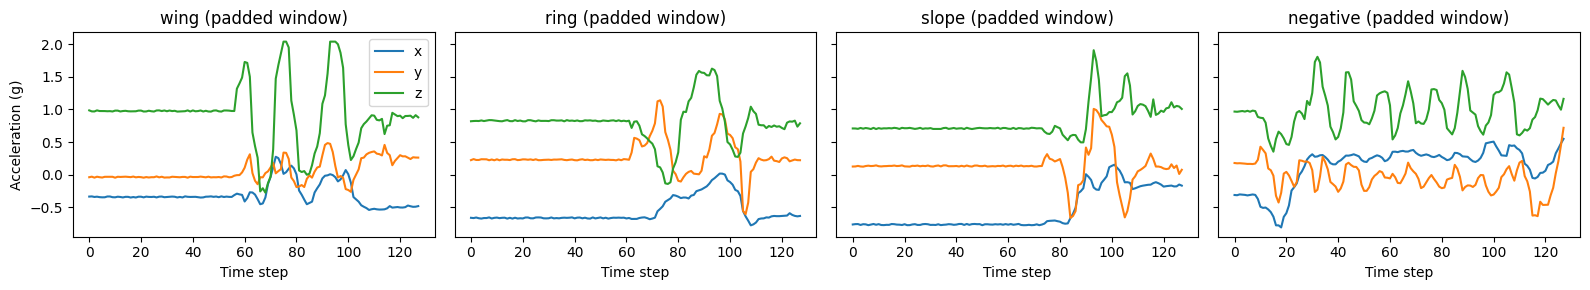

In [7]:
# Visual sanity check: one padded training window per class.
fig, axes = plt.subplots(1, len(GESTURES), figsize=(16, 3), sharey=True)
for k, g in enumerate(GESTURES):
    idx = np.where(y_train == k)[0][0]
    axes[k].plot(x_train[idx, :, :, 0])
    axes[k].set(title=f"{g} (padded window)", xlabel="Time step")
axes[0].set_ylabel("Acceleration (g)")
axes[0].legend(["x", "y", "z"])
plt.tight_layout()
plt.show()

## 5. Baseline model

The architecture is exactly as given in the spec:

| Layer | Configuration | Output |
|---|---|---|
| Input | 128 x 3 x 1 | 128x3x1 |
| Conv2D | 8 filters, 4x3, stride 1, same, ReLU | 128x3x8 |
| MaxPool2D | 3x3, stride 3x3, valid | 42x1x8 |
| Dropout | 0.1 | |
| Conv2D | 16 filters, 4x1, stride 1, same, ReLU | 42x1x16 |
| MaxPool2D | 3x1, stride 3x1, same | 14x1x16 |
| Dropout | 0.1 | |
| Flatten | | 224 |
| Dense | 16, ReLU | 16 |
| Dropout | 0.1 | |
| Dense | 4, Softmax | 4 |

In [8]:
def build_model():
    return tf.keras.Sequential([
        tf.keras.layers.Input(shape=(SEQ_LEN, DIM, 1), name="accel_input"),
        tf.keras.layers.Conv2D(8, (4, 3), strides=1, padding="same", activation="relu", name="conv1"),
        tf.keras.layers.MaxPool2D((3, 3), strides=(3, 3), padding="valid", name="pool1"),
        tf.keras.layers.Dropout(0.1, name="drop1"),
        tf.keras.layers.Conv2D(16, (4, 1), strides=1, padding="same", activation="relu", name="conv2"),
        tf.keras.layers.MaxPool2D((3, 1), strides=(3, 1), padding="same", name="pool2"),
        tf.keras.layers.Dropout(0.1, name="drop2"),
        tf.keras.layers.Flatten(name="flatten"),
        tf.keras.layers.Dense(16, activation="relu", name="fc1"),
        tf.keras.layers.Dropout(0.1, name="drop3"),
        tf.keras.layers.Dense(len(GESTURES), activation="softmax", name="fc2"),
    ], name="magic_wand_fp32")


model = build_model()
model.summary()



Model: "magic_wand_fp32"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv1 (Conv2D)              (None, 128, 3, 8)         104       
                                                                 
 pool1 (MaxPooling2D)        (None, 42, 1, 8)          0         
                                                                 
 drop1 (Dropout)             (None, 42, 1, 8)          0         
                                                                 
 conv2 (Conv2D)              (None, 42, 1, 16)         528       
                                                                 
 pool2 (MaxPooling2D)        (None, 14, 1, 16)         0         
                                                                 
 drop2 (Dropout)             (None, 14, 1, 16)         0         
                                                                 
 flatten (Flatten)           (None, 224)         

## 6. Training

Training uses Adam (lr = 1e-3), sparse categorical cross-entropy and batch size 64. Training stops early on validation loss, and the weights with the best validation accuracy are restored. The test set is used only once, in Section 7.

In [9]:
EPOCHS = 100
BATCH_SIZE = 64

model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

ckpt_path = MODEL_DIR / "best_val.weights.h5"
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(str(ckpt_path), monitor="val_accuracy", mode="max",
                                       save_best_only=True, save_weights_only=True),
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=15),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=6, min_lr=1e-5),
]

history = model.fit(x_train, y_train,
                    validation_data=(x_val, y_val),
                    epochs=EPOCHS, batch_size=BATCH_SIZE, shuffle=True,
                    callbacks=callbacks, verbose=2)

model.load_weights(str(ckpt_path))   # restore the best validation checkpoint

Epoch 1/100


197/197 - 2s - loss: 0.7766 - accuracy: 0.6908 - val_loss: 0.5929 - val_accuracy: 0.8043 - lr: 0.0010 - 2s/epoch - 11ms/step
Epoch 2/100
197/197 - 1s - loss: 0.2013 - accuracy: 0.9377 - val_loss: 0.6085 - val_accuracy: 0.8587 - lr: 0.0010 - 1s/epoch - 5ms/step
Epoch 3/100
197/197 - 1s - loss: 0.1195 - accuracy: 0.9659 - val_loss: 0.5665 - val_accuracy: 0.8587 - lr: 0.0010 - 1s/epoch - 5ms/step
Epoch 4/100
197/197 - 1s - loss: 0.0889 - accuracy: 0.9749 - val_loss: 0.5301 - val_accuracy: 0.8587 - lr: 0.0010 - 1s/epoch - 6ms/step
Epoch 5/100
197/197 - 1s - loss: 0.0747 - accuracy: 0.9789 - val_loss: 0.5205 - val_accuracy: 0.8478 - lr: 0.0010 - 1s/epoch - 6ms/step
Epoch 6/100
197/197 - 1s - loss: 0.0649 - accuracy: 0.9828 - val_loss: 0.4597 - val_accuracy: 0.8587 - lr: 0.0010 - 1s/epoch - 6ms/step
Epoch 7/100
197/197 - 1s - loss: 0.0530 - accuracy: 0.9862 - val_loss: 0.5168 - val_accuracy: 0.8478 - lr: 0.0010 - 1s/epoch - 6ms/step
Epoch 8/100
197/197 - 1s - loss: 0.0469 - acc

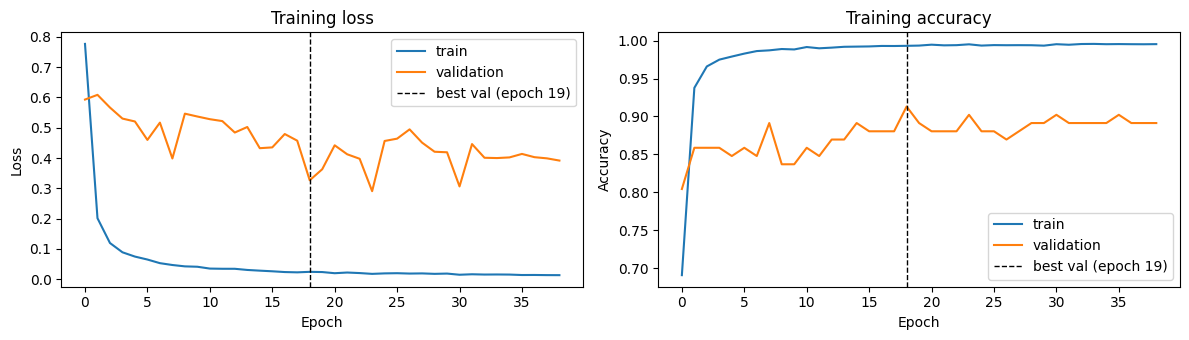

In [13]:
hist = history.history
best_epoch = int(np.argmax(hist["val_accuracy"])) + 1
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for ax, key, label in [(axes[0], "loss", "Loss"), (axes[1], "accuracy", "Accuracy")]:
    ax.plot(hist[key], label="train")
    ax.plot(hist[f"val_{key}"], label="validation")
    ax.axvline(best_epoch - 1, color="k", ls="--", lw=1, label=f"best val (epoch {best_epoch})")
    ax.set(title=f"Training {label.lower()}", xlabel="Epoch", ylabel=label)
    ax.legend()
plt.tight_layout()
plt.show()

## 7. Evaluation on the held-out test set

train loss=0.0096  accuracy=99.73%
val   loss=0.3265  accuracy=91.30%
test  loss=0.3525  accuracy=90.97%

              precision    recall  f1-score   support

        wing      1.000     0.854     0.921        41
        ring      0.894     1.000     0.944        42
       slope      0.896     0.977     0.935        44
    negative      0.840     0.750     0.792        28

    accuracy                          0.910       155
   macro avg      0.907     0.895     0.898       155
weighted avg      0.913     0.910     0.908       155



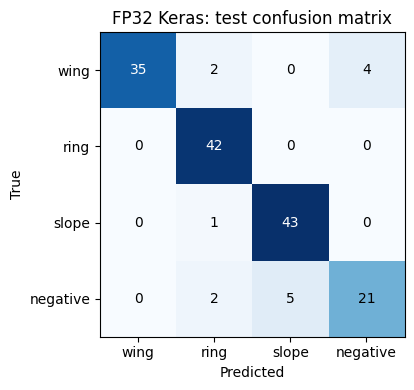

Requirement met: test accuracy 90.97% >= 90%


In [10]:
results = {}
for name, (X, y) in {"train": (x_train, y_train), "val": (x_val, y_val), "test": (x_test, y_test)}.items():
    loss, acc = model.evaluate(X, y, verbose=0)
    results[name] = {"loss": float(loss), "accuracy": float(acc)}
    print(f"{name:5s} loss={loss:.4f}  accuracy={acc * 100:.2f}%")

test_probs = model.predict(x_test, verbose=0)
test_pred = test_probs.argmax(axis=1)
print()
print(classification_report(y_test, test_pred, target_names=GESTURES, digits=3))

cm = confusion_matrix(y_test, test_pred, labels=range(len(GESTURES)))
fig, ax = plt.subplots(figsize=(4.5, 4))
ax.imshow(cm, cmap="Blues")
ax.set(xticks=range(len(GESTURES)), yticks=range(len(GESTURES)),
       xticklabels=GESTURES, yticklabels=GESTURES,
       xlabel="Predicted", ylabel="True", title="FP32 Keras: test confusion matrix")
for i in range(len(GESTURES)):
    for j in range(len(GESTURES)):
        ax.text(j, i, cm[i, j], ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.tight_layout()
plt.show()

assert results["test"]["accuracy"] >= 0.90, "FP32 baseline is below the required 90% test accuracy"
print(f"Requirement met: test accuracy {results['test']['accuracy'] * 100:.2f}% >= 90%")

## 8. Store the model

* `magic_wand_fp32.keras`: full Keras model (architecture, weights and optimizer state). This is the starting point for PTQ and QAT later.
* `saved_model/`: TensorFlow SavedModel.
* `magic_wand_fp32.tflite`: FP32 TFLite flatbuffer for TFLite Micro (no quantization). It is checked against Keras on the test set below.
* `processed/test_set.npz`: exact test inputs, labels and Keras outputs, for the desktop-vs-device comparison.
* `training_summary.json`: metrics and configuration of this run.

In [11]:
keras_path = MODEL_DIR / "magic_wand_fp32.keras"
model.save(keras_path)
model.export(str(MODEL_DIR / "saved_model"))

converter = tf.lite.TFLiteConverter.from_keras_model(model)   # default = pure FP32, no optimizations
tflite_model = converter.convert()
tflite_path = MODEL_DIR / "magic_wand_fp32.tflite"
tflite_path.write_bytes(tflite_model)
print(f"Saved {keras_path.name}, saved_model/, {tflite_path.name} ({len(tflite_model):,} bytes)")

# Check: the TFLite FP32 model must reproduce the Keras predictions.
interp = tf.lite.Interpreter(model_content=tflite_model)
interp.allocate_tensors()
inp, out = interp.get_input_details()[0], interp.get_output_details()[0]
tflite_probs = np.empty_like(test_probs)
for i in range(len(x_test)):
    interp.set_tensor(inp["index"], x_test[i:i + 1])
    interp.invoke()
    tflite_probs[i] = interp.get_tensor(out["index"])[0]
tflite_acc = float((tflite_probs.argmax(1) == y_test).mean())
max_diff = float(np.abs(tflite_probs - test_probs).max())
print(f"TFLite test accuracy = {tflite_acc * 100:.2f}% | max |Keras - TFLite| prob diff = {max_diff:.2e}")
print("TFLite ops:", sorted({op["op_name"] for op in interp._get_ops_details()}))

INFO:tensorflow:Assets written to: c:\Users\youss\Downloads\HW_for_AI_project\models\fp32\saved_model\assets


INFO:tensorflow:Assets written to: c:\Users\youss\Downloads\HW_for_AI_project\models\fp32\saved_model\assets


Saved artifact at 'c:\Users\youss\Downloads\HW_for_AI_project\models\fp32\saved_model'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 128, 3, 1), dtype=tf.float32, name='accel_input')
Output Type:
  TensorSpec(shape=(None, 4), dtype=tf.float32, name=None)
Captures:
  1441013099328: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1441013099680: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1441013378208: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1441013378560: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1441013488272: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1441013488624: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1441016621888: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1441016622240: TensorSpec(shape=(), dtype=tf.resource, name=None)
INFO:tensorflow:Assets written to: C:\Users\youss\AppData\Local\Temp\tmp5nlt6k1y\assets


INFO:tensorflow:Assets written to: C:\Users\youss\AppData\Local\Temp\tmp5nlt6k1y\assets


Saved magic_wand_fp32.keras, saved_model/, magic_wand_fp32.tflite (20,668 bytes)
TFLite test accuracy = 90.97% | max |Keras - TFLite| prob diff = 1.79e-07
TFLite ops: ['CONV_2D', 'DELEGATE', 'FULLY_CONNECTED', 'MAX_POOL_2D', 'RESHAPE', 'SOFTMAX']


In [14]:
np.savez(PROCESSED_DIR / "test_set.npz",
         x=x_test, y=y_test, keras_probs=test_probs, tflite_probs=tflite_probs,
         users=np.array([s["user"] for s in splits["test"]]), gestures=np.array(GESTURES))

summary = {
    "tensorflow_version": tf.__version__,
    "seed": SEED,
    "gestures": GESTURES,
    "input_scale": INPUT_SCALE,
    "input_note": "model input = accelerometer mg * input_scale, shape (1,128,3,1), gesture aligned to window end",
    "split": SPLIT,
    "split_sizes": {k: len(v) for k, v in splits.items()},
    "train_windows_after_augmentation": int(len(x_train)),
    "extra_train_negatives": {"stream_crops": N_NEG_CROPS, "synthetic": 3 * N_SYNTH_PER_KIND},
    "epochs_run": len(hist["loss"]),
    "best_epoch": best_epoch,
    "params": int(model.count_params()),
    "metrics": results,
    "tflite": {"bytes": len(tflite_model), "test_accuracy": tflite_acc, "max_prob_diff_vs_keras": max_diff},
}
(MODEL_DIR / "training_summary.json").write_text(json.dumps(summary, indent=2))
print(json.dumps(summary, indent=2))

{
  "tensorflow_version": "2.15.1",
  "seed": 42,
  "gestures": [
    "wing",
    "ring",
    "slope",
    "negative"
  ],
  "input_scale": 0.001,
  "input_note": "model input = accelerometer mg * input_scale, shape (1,128,3,1), gesture aligned to window end",
  "split": {
    "train": [
      "hyw",
      "shiyun",
      "tangsy",
      "dengyl",
      "jiangyh",
      "xunkai",
      "negative3"
    ],
    "val": [
      "pengxl",
      "negative2",
      "negative4"
    ],
    "test": [
      "liucx",
      "zhangxy",
      "negative1",
      "negative5"
    ]
  },
  "split_sizes": {
    "train": 434,
    "val": 92,
    "test": 155
  },
  "train_windows_after_augmentation": 12584,
  "extra_train_negatives": {
    "stream_crops": 1000,
    "synthetic": 300
  },
  "epochs_run": 39,
  "best_epoch": 19,
  "params": 4300,
  "metrics": {
    "train": {
      "loss": 0.009610242210328579,
      "accuracy": 0.9972981810569763
    },
    "val": {
      "loss": 0.32646796107292175,
      "acc